# Plotting the total number density of CR protons and electrons

In [1]:
import h5py
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
import numpy as np
import json

import matplotlib.lines as mlines

In [2]:
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/cr_bowshock_outputs"
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/emission"
data_dir = "/home/kwatanabe/Projects/cr-bowshocks/crbowshock_analysis_tools/data"

bowshock_config = json.load(open("../../config/bowshock_config.json", "r"))["config"]

In [3]:
species_lss = ["-", "--"]

species_handles = [
    mlines.Line2D([0], [0], ls="-", label="Proton", color="k"),
    mlines.Line2D([0], [0], ls="--", label="Electron", color="k")
]

/tmp/ipykernel_374689/2771357311.py:11: RuntimeWarning: invalid value encountered in divide
  print(pf[sim_name]["electron"]["ncr_mean"][()] / pf[sim_name]["proton"]["ncr_mean"][()])


[       nan 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885]
[       nan 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885]
[       nan 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.00179885]
[       nan 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885 0.00179885
 0.00179885 0.00179885 0.

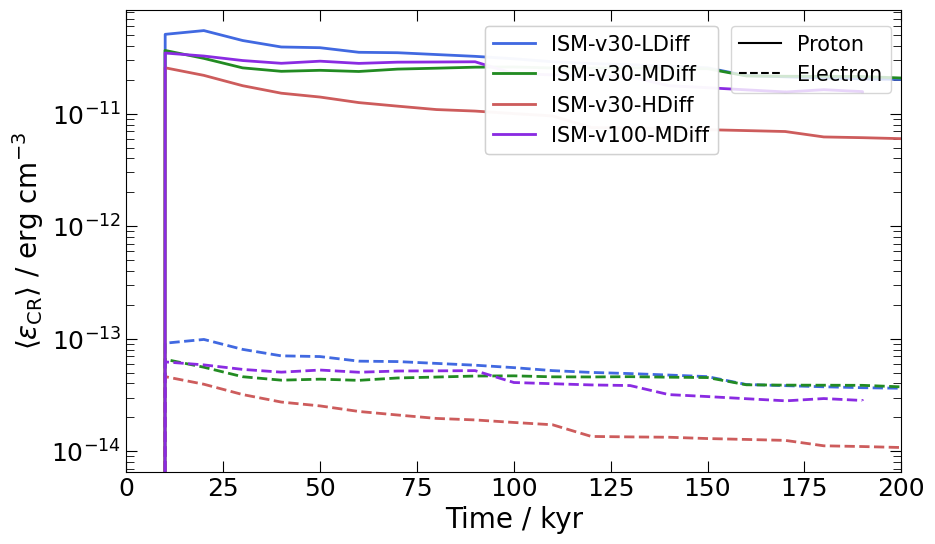

In [4]:
fig_tseries, ax_tseries = plt.subplots(figsize=(10, 6))

sim_handles=[]
for i, sim_name in enumerate(list(bowshock_config.keys())):
    # write data to h5py file
    with h5py.File(f"{data_dir}/emission_data_ncr.h5", "r") as pf:
        if sim_name not in list(pf.keys()):
            continue
        times = pf[sim_name]["proton/times"][()]

        print(pf[sim_name]["electron"]["ncr_mean"][()] / pf[sim_name]["proton"]["ncr_mean"][()])

        for ispec, spec in enumerate(["proton", "electron"]):
            ncr_tot = pf[sim_name][spec]["ncr_mean"][()]

            ax_tseries.semilogy(
                times[np.argsort(times)],
                ncr_tot[np.argsort(times)],
                color=bowshock_config[sim_name]["color"],
                label=sim_name,
                ls=species_lss[ispec],
                lw=2.0
            )

    sim_handles.append(
        mlines.Line2D(
            [0],
            [0],
            lw=2.0,
            color=bowshock_config[sim_name]["color"],
            label=bowshock_config[sim_name]["label"],
        )
    )

ax_tseries.set_xlabel("Time / kyr", fontsize=20)
ax_tseries.set_ylabel(r"$\langle \epsilon_\mathrm{CR} \rangle$ / erg cm$^{-3}$", fontsize=20)

# limits
ax_tseries.set_xlim(xmin=0, xmax=200)
# ax_tseries.set_ylim(ymin=1e-10, ymax=5e-5)

# ticks
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="major",
    size=8,
    labelsize=18,
    right=True,
    top=True,
)
ax_tseries.tick_params(
    axis="both",
    direction="in",
    which="minor",
    size=6,
    labelsize=16,
    right=True,
    top=True,
)

leg1 = fig_tseries.legend(
    handles=sim_handles,
    prop={"size": 15},
    loc="upper center",
    bbox_to_anchor=[0.6, 0.87]
)
fig_tseries.add_artist(leg1)
fig_tseries.legend(handles=species_handles, prop={"size": 15},
    loc="upper right",
    bbox_to_anchor=[0.9, 0.87])
# ax_tseries.legend(prop={"size": 15}, loc="upper left", bbox_to_anchor=[0.05, 0.98])

# save
fig_tseries.savefig(
    f"{fig_dir}/ncr/ncr_timeseries.pdf", bbox_inches="tight", dpi=300
)